# Latent qGAN with fixed evaluation and checkpoints

Separate copy of `GAN_01_latent4.ipynb`. Circuit, latent training batch (4),
random prior, unseeded sampler, optimizer settings, losses and 50-epoch update
order are unchanged. Added diagnostics do not consume the training RNG or
quantum measurement samples.

After each epoch, evaluate the same 64 latent vectors using noiseless circuit
probabilities. Also evaluate the exact uniform-prior marginal using the validated
16-point quadrature for this circuit. Save best, latest and final checkpoints
under `latent_monitor_results`, including generator/discriminator weights,
optimizer states, fixed evaluation inputs and Torch RNG state. Best is selected
by exact marginal KL, not the noisy training-batch curve. Epoch 0 is eligible.

Training-batch KL is measured before the update; fixed and exact evaluation are
measured after it. The final monitoring figure makes these distinctions explicit.
Checkpoint RNG state does not reproduce the unseeded sampler's random draws.
No early stopping or automatic loading of the best model is applied. Final
tutorial plots still show the final model, not the best checkpoint.


# Quantum qGAN — stage 1: four-dimensional latent input

This separate notebook preserves `GAN_01.ipynb`. It retains the tutorial's
six-qubit, 64-outcome distribution generator, `SamplerQNN`, `TorchConnector`,
84 trainable ansatz parameters, classical discriminator, and weighted losses.
Four `Ry(z[i])` rotations after the Hadamards encode a uniform latent prior
on [-pi, pi]^4. Latent parameters are explicitly separated from weights.
Training averages four conditional distributions; final plots average 32.
Input gradients are enabled for future encoder integration.

This stage still models the original two-dimensional Gaussian grid. The image
decoder, four-qubit encoder, pair discriminator, and BiGAN objective belong to
later stages after this change is validated and the dataset is identified.

Reference: [Qiskit PyTorch qGAN tutorial](https://qiskit-community.github.io/qiskit-machine-learning/tutorials/04_torch_qgan.html).
Run `validate_latent_generator.py` with the DOUBT_QC interpreter for a short
forward/backward and two-epoch training check without running all 50 epochs.


In [1]:
import torch
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = 123456
_ = torch.manual_seed(123456)  # suppress output

In [2]:
import numpy as np

latent_dim = 4
latent_batch_size = 4

num_dim = 2
num_discrete_values = 8
num_qubits = num_dim * int(np.log2(num_discrete_values))

In [3]:
from scipy.stats import multivariate_normal

coords = np.linspace(-2, 2, num_discrete_values)
rv = multivariate_normal(mean=[0.0, 0.0], cov=[[1, 0], [0, 1]], seed=algorithm_globals.random_seed)
grid_elements = np.transpose([np.tile(coords, len(coords)), np.repeat(coords, len(coords))])
prob_data = rv.pdf(grid_elements)
prob_data = prob_data / np.sum(prob_data)

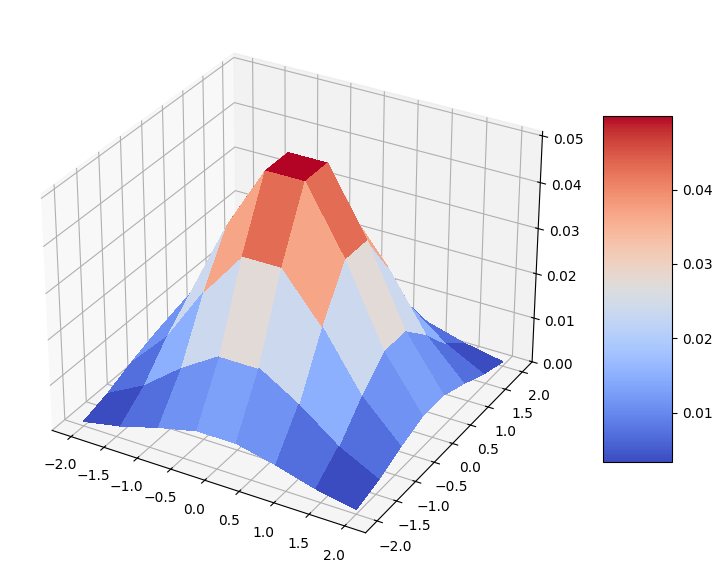

In [4]:
import matplotlib.pyplot as plt
from matplotlib import cm

mesh_x, mesh_y = np.meshgrid(coords, coords)
grid_shape = (num_discrete_values, num_discrete_values)

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={"projection": "3d"})
prob_grid = np.reshape(prob_data, grid_shape)
surf = ax.plot_surface(mesh_x, mesh_y, prob_grid, cmap=cm.coolwarm, linewidth=0, antialiased=False)
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import efficient_su2
from qiskit.circuit import ParameterVector

qc = QuantumCircuit(num_qubits)
qc.h(qc.qubits)

# Four independent latent inputs; the six-qubit output grid is unchanged.
latent_params = ParameterVector("z", latent_dim)
for qubit, angle in enumerate(latent_params):
    qc.ry(angle, qubit)

ansatz = efficient_su2(num_qubits, reps=6)
qc.compose(ansatz, inplace=True)

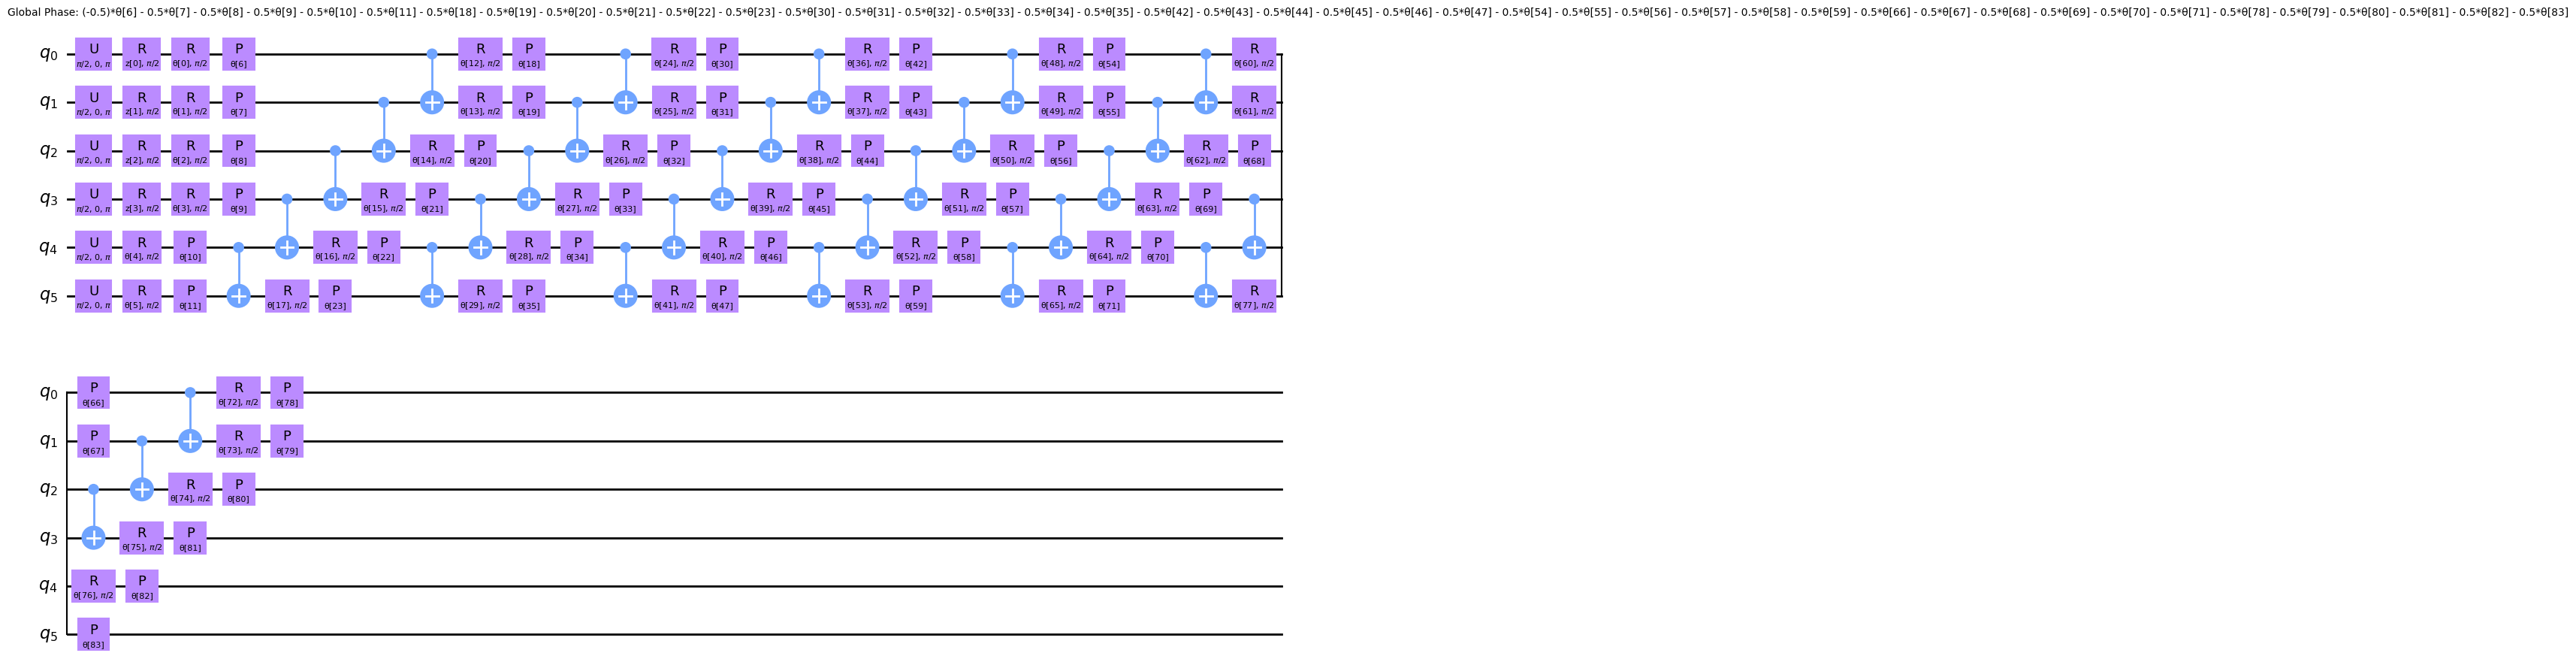

In [6]:
qc.decompose().draw(output="mpl", style="clifford")

In [7]:
qc.num_parameters

88

In [8]:
from qiskit.primitives import StatevectorSampler as Sampler

sampler = Sampler()

In [9]:
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import SamplerQNN


def create_generator() -> TorchConnector:
    qnn = SamplerQNN(
        circuit=qc,
        sampler=sampler,
        input_params=list(latent_params),
        weight_params=list(ansatz.parameters),
        input_gradients=True,
        sparse=False,
    )

    initial_weights = algorithm_globals.random.random(ansatz.num_parameters)
    return TorchConnector(qnn, initial_weights)

In [10]:
from torch import nn


class Discriminator(nn.Module):
    def __init__(self, input_size):
        super(Discriminator, self).__init__()

        self.linear_input = nn.Linear(input_size, 20)
        self.leaky_relu = nn.LeakyReLU(0.2)
        self.linear20 = nn.Linear(20, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        x = self.linear_input(input)
        x = self.leaky_relu(x)
        x = self.linear20(x)
        x = self.sigmoid(x)
        return x

In [11]:
generator = create_generator()
discriminator = Discriminator(num_dim)

In [12]:
def adversarial_loss(input, target, w):
    bce_loss = target * torch.log(input) + (1 - target) * torch.log(1 - input)
    weighted_loss = w * bce_loss
    total_loss = -torch.sum(weighted_loss)
    return total_loss

In [13]:
from torch.optim import Adam

lr = 0.01  # learning rate
b1 = 0.7  # first momentum parameter
b2 = 0.999  # second momentum parameter

generator_optimizer = Adam(generator.parameters(), lr=lr, betas=(b1, b2), weight_decay=0.005)
discriminator_optimizer = Adam(
    discriminator.parameters(), lr=lr, betas=(b1, b2), weight_decay=0.005
)

In [14]:
from latent_training_monitor import LatentTrainingMonitor
from pathlib import Path

# Own RNG for evaluation; random training inputs and sampler remain unchanged.
monitor = LatentTrainingMonitor(globals(), Path("latent_monitor_results"), evaluation_count=64)
monitor.record(0)


Epoch 0: training batch KL=None; fixed KL=0.54688; exact marginal KL=0.51008; best epoch=0


{'epoch': 0,
 'training_batch_kl': None,
 'kl_generated_to_target': 0.5100764277917211,
 'total_variation': 0.38373803062242906,
 'fixed_latent_kl': 0.5468768311975507,
 'fixed_vs_exact_tv': 0.04911915716769935}

In [15]:
from IPython.display import clear_output


def plot_training_progress():
    # we don't plot if we don't have enough data
    if len(generator_loss_values) < 2:
        return

    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))

    # Generator Loss
    ax1.set_title("Loss")
    ax1.plot(generator_loss_values, label="generator loss", color="royalblue")
    ax1.plot(discriminator_loss_values, label="discriminator loss", color="magenta")
    ax1.legend(loc="best")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Loss")
    ax1.grid()

    # Relative Entropy
    ax2.set_title("Relative entropy")
    ax2.plot(entropy_values)
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Relative entropy")
    ax2.grid()

    plt.show()

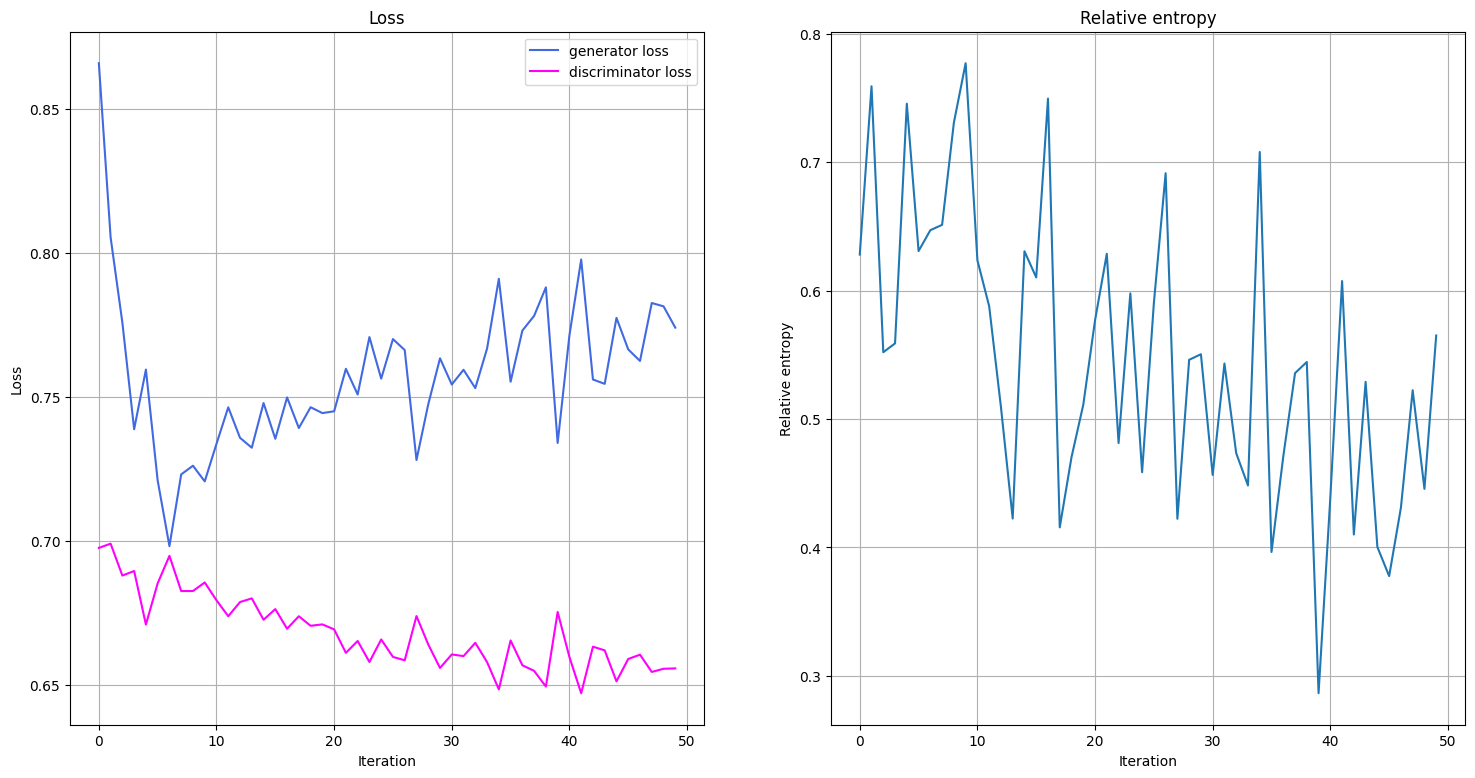

Fit in 488.18 sec


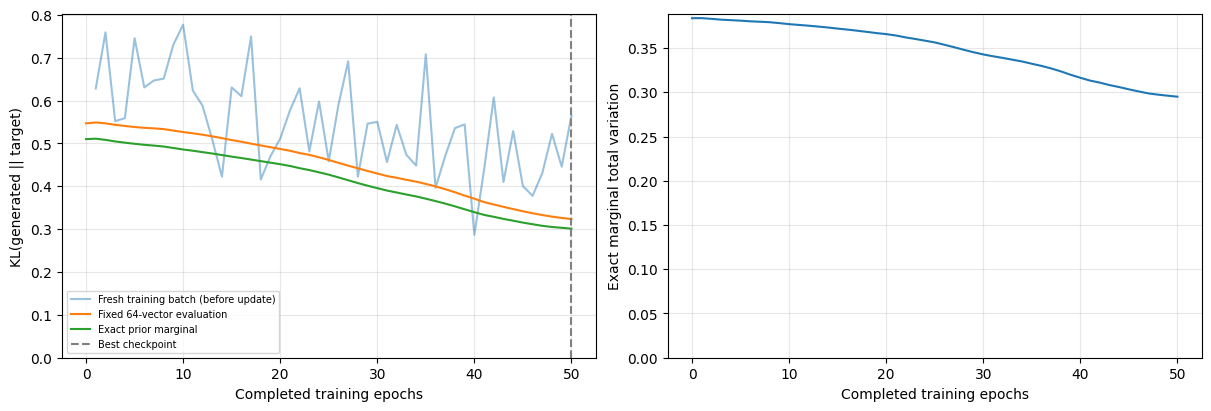

{'best_epoch': 50, 'best_exact_kl': 0.3010450932204029, 'final_epoch': 50, 'final_metrics': {'kl_generated_to_target': 0.3010450932204029, 'total_variation': 0.29502262602455376, 'fixed_latent_kl': 0.3235341154568376, 'fixed_vs_exact_tv': 0.04833573919322483}, 'best_to_final_kl_increase': 0.0, 'fixed_evaluation_vectors': 64, 'selection_metric': 'KL of noiseless exact uniform-prior marginal', 'training_unchanged': True, 'sampler_seed': None}


In [16]:
import time
from scipy.stats import multivariate_normal, entropy

n_epochs = 50

num_qnn_outputs = num_discrete_values**num_dim

generator_loss_values = []
discriminator_loss_values = []
entropy_values = []

start = time.time()
for epoch in range(n_epochs):

    valid = torch.ones(num_qnn_outputs, 1, dtype=torch.float)
    fake = torch.zeros(num_qnn_outputs, 1, dtype=torch.float)

    # Configure input
    real_dist = torch.tensor(prob_data, dtype=torch.float).reshape(-1, 1)

    # Configure samples
    samples = torch.tensor(grid_elements, dtype=torch.float)
    disc_value = discriminator(samples)

    # Generate data
    z = (2 * torch.rand(latent_batch_size, latent_dim) - 1) * torch.pi
    gen_dist = generator(z).mean(dim=0).reshape(-1, 1)

    # Train generator
    generator_optimizer.zero_grad()
    generator_loss = adversarial_loss(disc_value, valid, gen_dist)

    # store for plotting
    generator_loss_values.append(generator_loss.detach().item())

    generator_loss.backward(retain_graph=True)
    generator_optimizer.step()

    # Train Discriminator
    discriminator_optimizer.zero_grad()

    real_loss = adversarial_loss(disc_value, valid, real_dist)
    fake_loss = adversarial_loss(disc_value, fake, gen_dist.detach())
    discriminator_loss = (real_loss + fake_loss) / 2

    # Store for plotting
    discriminator_loss_values.append(discriminator_loss.detach().item())

    discriminator_loss.backward()
    discriminator_optimizer.step()

    entropy_value = entropy(gen_dist.detach().squeeze().numpy(), prob_data)
    entropy_values.append(entropy_value)

    monitor.record(epoch + 1, training_batch_kl=entropy_value)
    plot_training_progress()

elapsed = time.time() - start
print(f"Fit in {elapsed:0.2f} sec")
monitor_summary = monitor.finish()
print(monitor_summary)


In [17]:
with torch.no_grad():
    # Estimate the marginal distribution over the same uniform latent prior.
    z_eval = (2 * torch.rand(32, latent_dim) - 1) * torch.pi
    generated_probabilities = generator(z_eval).mean(dim=0).numpy()

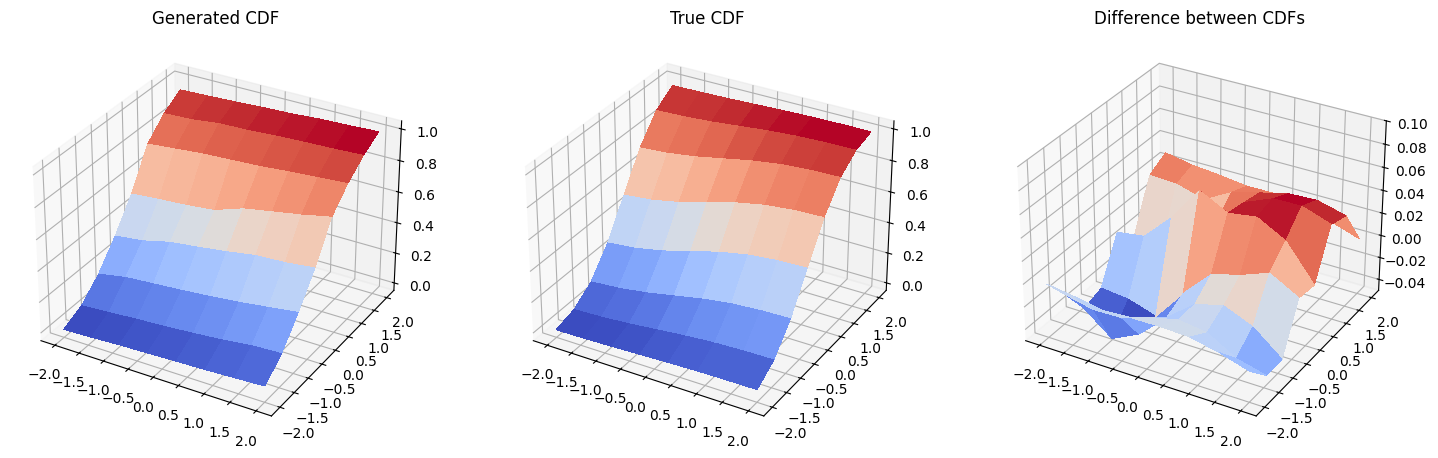

In [18]:
fig = plt.figure(figsize=(18, 9))

# Generated CDF
gen_prob_grid = np.reshape(np.cumsum(generated_probabilities), grid_shape)

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.set_title("Generated CDF")
ax1.plot_surface(mesh_x, mesh_y, gen_prob_grid, linewidth=0, antialiased=False, cmap=cm.coolwarm)
ax1.set_zlim(-0.05, 1.05)

# Real CDF
real_prob_grid = np.reshape(np.cumsum(prob_data), grid_shape)

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.set_title("True CDF")
ax2.plot_surface(mesh_x, mesh_y, real_prob_grid, linewidth=0, antialiased=False, cmap=cm.coolwarm)
ax2.set_zlim(-0.05, 1.05)

# Difference
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.set_title("Difference between CDFs")
ax3.plot_surface(
    mesh_x, mesh_y, real_prob_grid - gen_prob_grid, linewidth=2, antialiased=False, cmap=cm.coolwarm
)
ax3.set_zlim(-0.05, 0.1)
plt.show()

In [19]:
from importlib.metadata import PackageNotFoundError, version

for pkg in ("qiskit", "qiskit-machine-learning", "torch", "numpy", "scipy", "matplotlib"):
    try:
        print(f"{pkg:<26}{version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg:<26}not installed")

qiskit                    2.3.1
qiskit-machine-learning   0.9.1
torch                     2.14.1+cpu
numpy                     2.3.2
scipy                     1.16.1
matplotlib                3.10.5
